# Week 9 Class Demo 2: KNN Regression for Healthcare Cost Forecasting
## Predicting healthcare cost from similar historical profiles

**Emphasis:** similarity, model selection, and managerial trade-offs

## Learning and review resources

Use the resources in this order. This notebook is the main guided-review resource.

1. [Lecture 16 recording](https://nait.video.yuja.com/V/Video?v=1347394&node=7565692&a=1446991876)
4. [Lecture 16 notebook](https://nbviewer.org/github/Dong2Yo/PredcitiveAnalysis_BusinessProfessional/blob/main/lectures/Lecture16_beginning_regression_part_2.ipynb)
5. [Lecture 15–16 workbook](https://github.com/Dong2Yo/PredcitiveAnalysis_BusinessProfessional/blob/main/workbooks/Lecture15_16_workbook.ipynb)
6. [Supplementary least-angle regression PDF](https://github.com/Dong2Yo/PredcitiveAnalysis_BusinessProfessional/blob/main/lectures/Lecture16_LEAST_%20ANGLE_REGRESSION.pdf)
7. [*Machine Learning with Python for Everyone*](https://learning.oreilly.com/library/view/machine-learning-with/9780134845708/): Chapter 4, Chapter 5, and Chapter 7 through the NAIT O’Reilly subscription.

### Autonomous-learning routine
1. Read the theory before running code.
2. Predict what the output will mean.
3. Run the supplied code. You are not expected to write the model from scratch.
4. Interpret the output in business language.
5. Open the collapsible answer only after drafting your response.
6. Ask whether the evidence supports a decision, not merely whether the code runs.

## 🎯 Learning Objectives

By the end of this class demo, you should be able to:

1. **Explain how K-Nearest Neighbors (KNN) Regression works** and identify business problems where it can be used to predict a continuous numerical outcome.

2. **Explain how KNN makes a prediction** by finding similar observations and using the target values of the nearest neighbors.

3. **Identify the target (`y`) and predictor variables (`X`)** and explain whether the selected variables create a meaningful definition of “similarity.”

4. **Explain why feature scaling is important for KNN**, especially when predictors use different units or numerical ranges.

5. **Build and run a KNN Regression model** using a provided Python/scikit-learn workflow without needing to memorize the code.

6. **Explain the role of `k`** and how changing the number of neighbors affects model behaviour:
   - smaller `k` → more flexible and potentially more sensitive to individual observations;
   - larger `k` → smoother predictions that may overlook useful local patterns.

7. **Recognize underfitting and overfitting** by comparing training and validation performance across different values of `k`.

8. **Use cross-validation to choose model settings** rather than repeatedly selecting parameters based on the final test set.

9. **Evaluate KNN Regression performance** using:
   - Mean Absolute Error (MAE)
   - Mean Squared Error (MSE)
   - Root Mean Squared Error (RMSE)
   - R² Score

10. **Inspect the nearest neighbors behind an individual prediction** and determine whether those observations appear to be reasonable comparisons.

11. **Compare KNN Regression with Linear Regression** using the same test data and evaluation metrics.

12. **Evaluate model trade-offs** involving predictive performance, interpretability, stability, preprocessing, and business usefulness.

13. **Apply KNN Regression to a new business problem**, such as forecasting sales for a new retail location based on similar existing stores.

14. **Transfer the KNN modelling and interpretation process to Assignment 1**, where you will select features, evaluate models, justify model choices, and interpret the prediction of `wage_eur`.

> ### 💡 BBA Focus
>
> You are **not expected to memorize the Python code for KNN Regression**.
>
> Instead, focus on being able to explain:
>
> **What are we predicting? → What makes two observations “similar”? → Why do we scale the data? → How was `k` selected? → How well does the model perform? → Are the neighbors reasonable? → Should we use this model for the business decision?**
>
> Generative AI can help you create or troubleshoot modelling code, but **you must be able to interpret the results, justify the modelling decisions, identify limitations, and communicate the recommendation in business language.**

## Connection to Assignment 1: Regression Modelling & Evaluations

Assignment 1 uses a different business context: predicting **`wage_eur` for FIFA soccer players**. The modelling workflow in this healthcare demonstration transfers directly, but your Assignment 1 decisions must be based on the FIFA data rather than copied from this notebook.

Assignment 1 emphasizes the quality of your **decisions, explanations, and iteration**, not simply finding the model with the best score. Use this demo as a worked example of how to:

1. load and preview a dataset;
2. clean and transform relevant fields;
3. select features using evidence and domain logic;
4. create and justify a train-test split;
5. train at least one regression model;
6. evaluate the model with appropriate metrics;
7. identify a limitation or unexpected result and revise the approach;
8. explain what the final result means in business language.

> **Academic-work reminder:** Generative AI may help you understand syntax or troubleshoot code, but your submitted notebook must reflect your group's own choices, outputs, interpretation, and reflection. Generic explanations that do not match your code and results will not demonstrate the required learning.

## Theory: KNN regression
For a new row, KNN measures distance to training rows, selects the k nearest rows, and averages their targets.

### Scaling
Distance combines feature differences. Without scaling, a variable with a large numerical range may dominate because of its units rather than business relevance. Scaling must be learned from training data to avoid leakage.

### Choosing k
- Small k is flexible but can overfit and become unstable.
- Large k is smoother but may combine meaningfully different cases and underfit.

KNN has no simple coefficient table. Interpretation therefore examines how similarity is defined, which neighbors drive a prediction, and whether the new case is well represented by historical data.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
RANDOM_STATE = 42
pd.set_option("display.precision", 2)

In [77]:
# Load the same healthcare dataset used in Week 8.
# Keep the CSV in the same folder as this notebook.


DATA_FILE = Path("ClassDemo_health_data.csv")
df = pd.read_csv(DATA_FILE)
print(f"Rows: {len(df):,}; columns: {df.shape[1]}")
df.head()

Rows: 65,000; columns: 11


,patient_id,age,bmi,systolic_bp,diastolic_bp,resting_hr,exercise_hours,sleep_hours,smoker,cholesterol,health_cost
0,P000001,51,23.1,118,68,75,2.1,7.6,No,211,6288
1,P000002,31,19.5,88,75,78,6.9,6.6,No,141,4930
2,P000003,22,24.2,112,67,74,2.2,5.9,No,185,4877
3,P000004,23,31.1,88,57,82,4.1,7.7,No,144,5148
4,P000005,49,31.3,132,60,66,4.1,7.4,Yes,217,6505


## Dataset and responsible-use boundary

This notebook reuses **`Wk8_ClassDemo_health_data.csv`** from Week 8 so that the emphasis shifts from understanding and preparing data to building and interpreting regression models.

| Field | Role in this notebook |
|---|---|
| `patient_id` | Identifier; excluded from modelling |
| `age` | Numeric predictor |
| `bmi` | Numeric predictor |
| `systolic_bp`, `diastolic_bp` | Numeric predictors |
| `resting_hr` | Numeric predictor |
| `exercise_hours`, `sleep_hours` | Numeric predictors |
| `smoker` | Categorical predictor encoded as 0/1 |
| `cholesterol` | Numeric predictor |
| `health_cost` | Continuous target predicted in dollars |

The file is teaching data. Model output supports learning about business analytics and should not be treated as clinical or insurance-pricing evidence.

In [9]:
def regression_metrics(y_true, prediction, model_name):
    return pd.Series({"Model":model_name,"MAE":mean_absolute_error(y_true,prediction),"MSE":mean_squared_error(y_true,prediction),"RMSE":mean_squared_error(y_true,prediction)**0.5,"R2":r2_score(y_true,prediction)})

In [10]:
model_df=df.sample(n=3000, random_state=RANDOM_STATE).copy()
model_df["smoker_yes"]=(model_df["smoker"].str.strip().str.lower()=="yes").astype(int)
features=["age","bmi","systolic_bp","diastolic_bp","resting_hr","exercise_hours","sleep_hours","smoker_yes","cholesterol"]
X=model_df[features]; y=model_df["health_cost"]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,random_state=RANDOM_STATE)
print(X_train.shape,X_test.shape)

(2400, 9) (600, 9)


## Supplied leakage-safe pipeline

For responsive in-class execution, the KNN demonstration uses a reproducible sample of **3,000 rows** from the 65,000-row Week 8 file. KNN repeatedly calculates distances, so using the full file during three-fold tuning would add processing time without adding a new learning objective. The same sampled rows and random seed are used each time.

Students are not expected to create this script from memory. Explain the business purpose of the steps: scaling creates a balanced distance space, KNN finds similar training rows, and the pipeline prevents test information from shaping preprocessing.


In [12]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
knn5=Pipeline([("scale",StandardScaler()),("knn",KNeighborsRegressor(n_neighbors=5))])
knn5.fit(X_train,y_train)
pred5=knn5.predict(X_test)
regression_metrics(y_test,pred5,"KNN, k=5")

Model     KNN, k=5
MAE         844.14
MSE      1071408.5
RMSE       1035.09
R2            0.52
dtype: object

### Check-in 1
Why are scaling and the train/test split necessary? Explain without discussing Python syntax.

<details>
<summary><strong>Model answer</strong></summary>

Scaling prevents numeric units from arbitrarily controlling similarity. The split evaluates the fitted workflow on cases not used to build it, providing more credible evidence of generalization.

</details>

## Inspect one prediction
Focus on whether the mathematical definition of similarity appears meaningful for the business problem.

In [16]:
row=0
scaled=knn5.named_steps["scale"].transform(X_test.iloc[[row]])
dist,idx=knn5.named_steps["knn"].kneighbors(scaled)
neighbors=X_train.iloc[idx[0]].copy(); neighbors["observed_health_cost"]=y_train.iloc[idx[0]].to_numpy(); neighbors["distance"]=dist[0]
print("Prediction:",pred5[row],"Actual:",y_test.iloc[row])
neighbors.sort_values("distance")

Prediction: 7910.4 Actual: 7533


,age,bmi,systolic_bp,diastolic_bp,resting_hr,exercise_hours,sleep_hours,smoker_yes,cholesterol,observed_health_cost,distance
27010,44,33.0,105,71,80,1.3,7.0,1,164,8024,0.64
1166,51,34.7,115,70,87,0.2,6.6,1,180,9558,1.24
23305,52,31.6,115,70,78,1.3,7.2,1,201,7140,1.35
48573,33,34.3,120,66,78,1.1,7.1,1,164,8312,1.47
6425,38,34.6,116,71,78,3.6,7.1,1,179,6518,1.51


### Check-in 2
Are the selected neighbors similar on every field? What important healthcare context is missing?

<details>
<summary><strong>Model answer</strong></summary>

A neighbor need not be closest on every field because distance combines all scaled features. Missing context could include diagnosis, procedure, discharge destination, complications, and hospital unit. These are discussion ideas, not represented variables.

</details>

## How k changes generalization
Training error rewards close fit to known rows. Cross-validation error is more useful for selecting k because each candidate is evaluated on held-out folds within the training data.

In [20]:
from sklearn.model_selection import KFold,cross_validate
cv=KFold(n_splits=3,shuffle=True,random_state=RANDOM_STATE)
rows=[]
for k in range(1,21):
    candidate=Pipeline([("scale",StandardScaler()),("knn",KNeighborsRegressor(n_neighbors=k))])
    scores=cross_validate(candidate,X_train,y_train,cv=cv,scoring="neg_mean_absolute_error",return_train_score=True)
    rows.append({"k":k,"Training MAE":-scores["train_score"].mean(),"Validation MAE":-scores["test_score"].mean()})
k_review=pd.DataFrame(rows)
k_review.head()

,k,Training MAE,Validation MAE
0,1,-0.00,1071.69
1,2,542.70,928.80
2,3,621.04,876.25
3,4,650.74,850.89
4,5,675.28,836.67


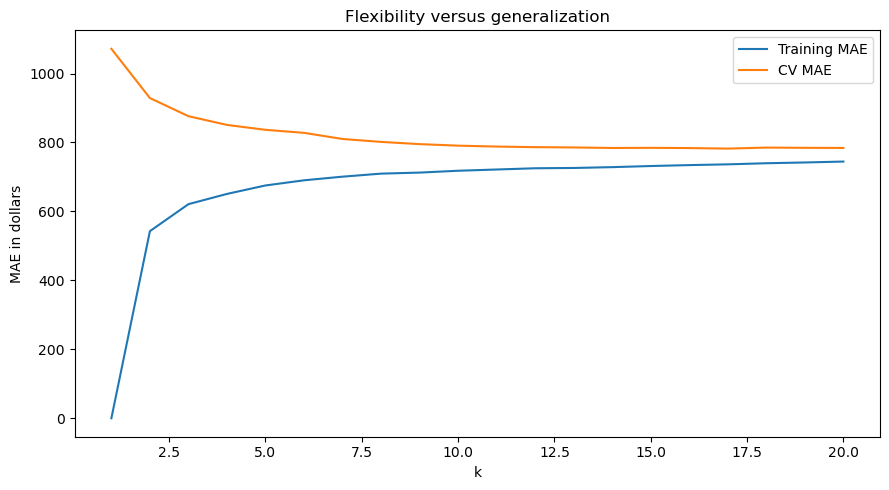

In [21]:
plt.figure(figsize=(9,5)); plt.plot(k_review["k"],k_review["Training MAE"],label="Training MAE"); plt.plot(k_review["k"],k_review["Validation MAE"],label="CV MAE"); plt.xlabel("k"); plt.ylabel("MAE in dollars"); plt.title("Flexibility versus generalization"); plt.legend(); plt.tight_layout(); plt.show()

### Check-in 3
Identify the likely overfitting region, best validation region, and overly smooth region. Why not select k from training error?

<details>
<summary><strong>Model answer</strong></summary>

Very small k usually creates the largest training-validation gap and suggests overfitting. The preferred region is where validation MAE is lowest. Very large k can oversmooth. Training error alone rewards memorization rather than future-case performance.

</details>

## Cross-validated model selection
The test set remains untouched while cross-validation chooses k and the weighting rule.

In [25]:
from sklearn.model_selection import GridSearchCV
pipe=Pipeline([("scale",StandardScaler()),("knn",KNeighborsRegressor())])
search=GridSearchCV(pipe,{"knn__n_neighbors":list(range(3,21)),"knn__weights":["uniform","distance"]},cv=cv,scoring="neg_mean_absolute_error",n_jobs=-1)
search.fit(X_train,y_train)
print("Selected settings:",search.best_params_)
print("Cross-validation MAE:",-search.best_score_)

Selected settings: {'knn__n_neighbors': 17, 'knn__weights': 'distance'}
Cross-validation MAE: 781.0691012007866


### Check-in 4
Why should analysts not repeatedly adjust k after looking at test-set performance?

<details>
<summary><strong>Model answer</strong></summary>

Repeated test-set use turns the test set into development data. The final result then becomes optimistically biased and no longer represents an untouched evaluation.

</details>

## Final comparison
Compare models on the same test rows. Consider whether a numerical advantage is large enough to justify differences in transparency and maintenance.

In [29]:
from sklearn.linear_model import LinearRegression
best_knn=search.best_estimator_; pred_knn=best_knn.predict(X_test)
lr=LinearRegression().fit(X_train,y_train); pred_lr=lr.predict(X_test)
baseline=np.repeat(y_train.mean(),len(y_test))
pd.DataFrame([regression_metrics(y_test,baseline,"Training-mean baseline"),regression_metrics(y_test,pred_lr,"Linear regression"),regression_metrics(y_test,pred_knn,"Tuned KNN")]).set_index("Model")

,MAE,MSE,RMSE,R2
Model,,,,
Training-mean baseline,1195.39,2.23e+06,1492.43,-2.47e-03
Linear regression,723.54,8.07e+05,898.17,6.37e-01
Tuned KNN,777.97,9.33e+05,965.95,5.80e-01


## Intriguing Example 1: Find the Patient’s “Digital Neighbours”

KNN can be introduced as a matching system. A new profile is predicted using historically similar records.

### The mystery
Two profiles may have similar age and BMI but differ on smoking, cholesterol, or blood pressure. KNN combines all scaled differences into one distance.

### Investigation steps
1. Select one test record.
2. retrieve its nearest neighbours.
3. compare the new record with those neighbours.
4. inspect neighbour costs.
5. decide whether the neighbours make business sense.

The machine can calculate proximity, but students must judge whether the chosen variables define meaningful similarity.

In [31]:
from IPython.display import display
mystery_row = 3
scaled_mystery = best_knn.named_steps["scale"].transform(X_test.iloc[[mystery_row]])
mystery_dist, mystery_idx = best_knn.named_steps["knn"].kneighbors(scaled_mystery)

mystery_profile = X_test.iloc[[mystery_row]].copy()
mystery_neighbors = X_train.iloc[mystery_idx[0]].copy()
mystery_neighbors["health_cost"] = y_train.iloc[mystery_idx[0]].to_numpy()
mystery_neighbors["distance"] = mystery_dist[0]

print("New profile:")
display(mystery_profile)
print(f"Predicted cost: ${best_knn.predict(X_test.iloc[[mystery_row]])[0]:,.0f}")
print("Closest digital neighbours:")
display(mystery_neighbors.sort_values("distance").head(8))

New profile:


,age,bmi,systolic_bp,diastolic_bp,resting_hr,exercise_hours,sleep_hours,smoker_yes,cholesterol
12114,23,28.1,99,56,72,1.8,9.3,0,167


Predicted cost: $5,172
Closest digital neighbours:


,age,bmi,systolic_bp,diastolic_bp,resting_hr,exercise_hours,sleep_hours,smoker_yes,cholesterol,health_cost,distance
47544,26,26.5,98,60,71,2.0,9.4,0,181,5552,0.78
7205,21,28.2,92,66,72,1.1,9.6,0,162,4717,1.46
43558,18,28.0,93,54,79,1.9,8.5,0,147,3625,1.46
43536,31,26.9,101,61,78,1.4,8.7,0,199,4482,1.62
31931,22,27.6,101,60,71,4.2,8.5,0,145,6164,1.63
54300,18,24.7,88,65,71,1.8,9.4,0,150,5002,1.68
19652,24,31.6,108,59,77,2.6,8.2,0,153,6098,1.71
56804,33,24.5,99,60,78,1.3,8.6,0,136,5695,1.75


### Neighbour jury
Vote **trust**, **use with caution**, or **do not trust yet**. Defend the vote using neighbour distances, feature similarity, and the costs of the neighbour records.

<details>
<summary><strong>Reveal suggested interpretation</strong></summary>

A defensible answer refers to the displayed evidence. Close distances and reasonably consistent neighbour costs support more confidence. Large distances, conflicting neighbour costs, or questionable similarity should reduce confidence. KNN always returns neighbours, but they are not always strong comparators.

</details>

## Intriguing Example 2: The Scaling Race

Imagine a similarity contest between two variables:

- BMI typically changes by tens of units.
- Cholesterol can change by hundreds of units.

Without scaling, cholesterol can dominate distance simply because its numbers are larger.

We compare the nearest neighbours found with and without scaling. If the neighbour lists differ, students can see that preprocessing changes the business meaning of “similar.”

In [35]:
from sklearn.neighbors import NearestNeighbors

query = X_test.iloc[[0]]
raw_nn = NearestNeighbors(n_neighbors=5).fit(X_train)
raw_dist, raw_idx = raw_nn.kneighbors(query)

scaled_query = best_knn.named_steps["scale"].transform(query)
scaled_dist, scaled_idx = best_knn.named_steps["knn"].kneighbors(scaled_query, n_neighbors=5)

comparison_neighbors = pd.DataFrame({
    "Raw-distance training index": X_train.index[raw_idx[0]].tolist(),
    "Scaled-distance training index": X_train.index[scaled_idx[0]].tolist()
})
comparison_neighbors

,Raw-distance training index,Scaled-distance training index
0,64962,27010
1,42817,1166
2,33198,23305
3,27010,48573
4,8913,6425


### Scaling-race check-in
If the two neighbour lists differ, which list is automatically correct? What business decision is hidden inside the choice to scale?

<details>
<summary><strong>Reveal suggested interpretation</strong></summary>

Neither list is automatically correct solely because it came from an algorithm. Scaling states that differences should be compared in standardized units rather than original measurement units. That is a modelling choice about what counts as similarity and should be justified for the business problem.

</details>

## Intriguing Example 3: The Neighbour Stability Test

A trustworthy recommendation should not change dramatically after a tiny, reasonable modelling adjustment. We compare predictions at nearby values of `k`.

### What to watch
- A large prediction swing suggests local instability.
- A small swing suggests the estimate is less sensitive to this particular choice.
- Stability does not prove correctness, but instability is a useful warning signal.

In [39]:
stability_rows = []
for k in [3, 5, 9, 15, 20]:
    stability_model = Pipeline([
        ("scale", StandardScaler()),
        ("knn", KNeighborsRegressor(n_neighbors=k, weights="distance"))
    ])
    stability_model.fit(X_train, y_train)
    stability_rows.append({
        "k": k,
        "prediction_for_same_record": stability_model.predict(X_test.iloc[[0]])[0]
    })
stability_table = pd.DataFrame(stability_rows)
stability_table

,k,prediction_for_same_record
0,3,8211.58
1,5,7974.40
2,9,7778.05
3,15,8140.23
4,20,8087.72


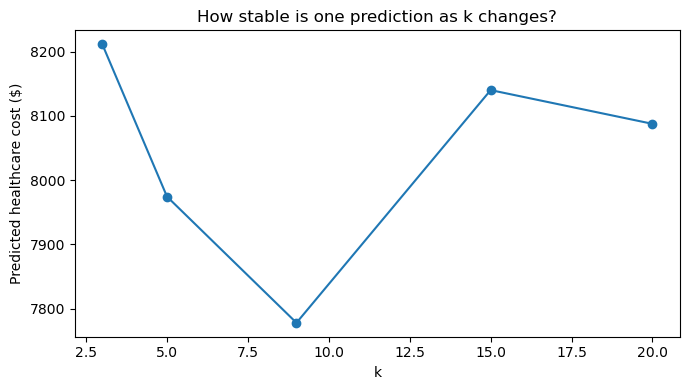

In [40]:
plt.figure(figsize=(7,4))
plt.plot(stability_table["k"], stability_table["prediction_for_same_record"], marker="o")
plt.xlabel("k")
plt.ylabel("Predicted healthcare cost ($)")
plt.title("How stable is one prediction as k changes?")
plt.tight_layout()
plt.show()

### Stability check-in
Would the prediction lead to a different business action at different values of `k`? If so, what should the analyst communicate?

<details>
<summary><strong>Reveal suggested interpretation</strong></summary>

The analyst should disclose that the recommendation is sensitive to model settings and should not present one selected prediction as inevitable. Additional data, validation, segmentation, or a more stable model may be needed.

</details>

## Intriguing Example 4: Recommendation Without an Algorithm Winner

Suppose KNN has a slightly lower MAE, but Linear Regression is easier to explain and monitor. There may be no universally correct winner.

### Mini board meeting
Assign roles:
- **Finance:** prioritizes the size and cost of errors.
- **Operations:** prioritizes usable and stable estimates.
- **Analytics:** prioritizes validation quality.
- **Governance:** prioritizes explainability and controls.

Each role recommends a model using the displayed comparison table. The group then writes one balanced final decision.

## Optional Assignment 1 Twist: Who Is a FIFA Player’s Nearest Neighbour?

For the FIFA wage assignment, ask students to select one player from the test set and inspect the training players KNN treats as similar.

Questions:
1. Do the neighbours make soccer and business sense?
2. Are positions or leagues being ignored?
3. Are superstar wages creating unstable local averages?
4. Does scaling make a player's skills more influential than age or another feature?
5. Would the recommendation change for an unusual player with no close neighbours?

Students should answer from their own features and results rather than copying a generic explanation.

## Student Try-It: A Different KNN Example — “Which Stores Are Most Like Ours?”

This example moves away from healthcare. Imagine a retail manager opening a new location and asking:

> **Based on similar stores, what daily sales should we expect?**

### Variables
- `floor_area`: store size in square metres
- `foot_traffic`: average daily visitors
- `near_transit`: 1 if close to a major transit stop, otherwise 0
- `daily_sales`: target in dollars

### Steps
1. Run the supplied small dataset.
2. Split predictors and target.
3. Scale predictors because KNN uses distance.
4. Fit KNN with a starting value of `k=3`.
5. Predict sales for the test stores.
6. Inspect MAE.
7. Change `k` and determine whether the conclusion is stable.
8. Predict sales for a new proposed store.

> **Assignment 1 connection:** In your FIFA work, the important question is similar: which players does KNN consider “nearby,” and does that definition of similarity make business sense?

In [86]:
# Small self-contained retail dataset: suitable for Google Colab
stores = pd.DataFrame({
    "floor_area":   [80,95,110,125,140,155,170,185,200,215,230,245,260,280,300,320],
    "foot_traffic": [120,150,160,190,210,230,250,270,310,320,350,370,400,430,460,500],
    "near_transit": [0,0,1,0,1,0,1,1,0,1,1,0,1,1,1,1],
    "daily_sales":  [1800,2100,2500,2600,3100,3200,3600,4000,3900,4500,4800,4700,5300,5700,6100,6600]
})
stores.head()

,floor_area,foot_traffic,near_transit,daily_sales
0,80,120,0,1800
1,95,150,0,2100
2,110,160,1,2500
3,125,190,0,2600
4,140,210,1,3100


In [88]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error

X_store = stores[["floor_area", "foot_traffic", "near_transit"]]
y_store = stores["daily_sales"]
X_train_store, X_test_store, y_train_store, y_test_store = train_test_split(
    X_store, y_store, test_size=0.25, random_state=42
)

store_knn = Pipeline([
    ("scale", StandardScaler()),
    ("knn", KNeighborsRegressor(n_neighbors=3))
])
store_knn.fit(X_train_store, y_train_store)
store_pred = store_knn.predict(X_test_store)
print(f"Test MAE: ${mean_absolute_error(y_test_store, store_pred):,.0f}")

Test MAE: $650


### Mini experiment: does k matter?
Run the next cell first as written. Then try values such as **3, 5, 7, and 9**. Do not select a value just because one run looks best. Explain what changes and why a validation procedure would be more defensible for formal model selection.

In [91]:
for k in [3, 5, 7, 9]:
    candidate = Pipeline([
        ("scale", StandardScaler()),
        ("knn", KNeighborsRegressor(n_neighbors=k))
    ])
    
    candidate.fit(X_train_store, y_train_store)
    pred = candidate.predict(X_test_store)

    print(
        f"k={k:>2}: test MAE = "
        f"${mean_absolute_error(y_test_store, pred):,.0f}"
    )

k= 3: test MAE = $650
k= 5: test MAE = $870
k= 7: test MAE = $1,093
k= 9: test MAE = $1,361


### New-store challenge
A proposed store will have:
- floor area = **210 m²**
- expected foot traffic = **335 visitors/day**
- near transit = **yes**

Predict daily sales using the `k=3` model. Then inspect the three historical training stores the model uses as neighbours.

In [51]:
proposed_store = pd.DataFrame({
    "floor_area": [210],
    "foot_traffic": [335],
    "near_transit": [1]
})

proposed_sales = store_knn.predict(proposed_store)[0]
print(f"Predicted daily sales: ${proposed_sales:,.0f}")

scaled_proposed = store_knn.named_steps["scale"].transform(proposed_store)
distance, index = store_knn.named_steps["knn"].kneighbors(scaled_proposed)
neighbor_stores = X_train_store.iloc[index[0]].copy()
neighbor_stores["daily_sales"] = y_train_store.iloc[index[0]].to_numpy()
neighbor_stores["distance"] = distance[0]
neighbor_stores

Predicted daily sales: $4,433


,floor_area,foot_traffic,near_transit,daily_sales,distance
9,215,320,1,4500,0.17
10,230,350,1,4800,0.36
7,185,270,1,4000,0.78


### Your interpretation questions
1. In ordinary business language, how does KNN create the proposed-store prediction?
2. Do the three neighbours look reasonably comparable to the proposed location?
3. Why was scaling necessary when floor area and foot traffic use different units?
4. How did changing `k` affect test MAE?
5. If the nearest stores were still very far away, what warning should accompany the prediction?

<details>
<summary><strong>Reveal suggested interpretation</strong></summary>

1. The model identifies the three most similar training stores after scaling the predictors and combines their observed sales to estimate sales for the proposed location.
2. Judge this from the displayed neighbour table; there is no automatic “yes” simply because KNN selected them.
3. Scaling prevents a variable from dominating distance merely because its numerical range is larger.
4. Use the printed results. The purpose is to observe sensitivity, not to memorize one best value from this tiny dataset.
5. The estimate has weak local support and should be treated cautiously rather than presented as equally reliable.

</details>

## BBA Interpretation Lab
Draft each answer before expanding the solution.

1. Why is variable importance harder to explain for KNN than linear regression?
2. KNN has a slightly lower MAE. Is that enough to select it for a dashboard?
3. What business problem occurs when k is too small?
4. What business problem occurs when k is too large?
5. Why be cautious when a new case is far from every training row?
6. Why is scaling a business issue, not merely a technical issue?
7. Explain repeated test-set tuning to a non-technical manager.
8. Give one business argument for linear regression and one for KNN.

<details>
<summary><strong>Model answer</strong></summary>

1. Linear regression supplies coefficients; KNN relies on combined distances and local neighbors. Interpretation must examine similarity and neighbor support.

2. No. The improvement must be operationally meaningful and weighed against transparency, stability, speed, maintenance, and monitoring.

3. Small k can make estimates unstable and overly sensitive to individual historical cases.

4. Large k can average together dissimilar cases and hide useful local patterns.

5. Distant neighbors mean weak historical support. Flag the prediction rather than treating it as equally reliable.

6. Scaling defines which cases count as similar. Units should not determine business relevance.

7. Repeatedly checking the test result while tuning is like studying from the final exam; the reported score becomes too optimistic.

8. Linear regression supports transparent coefficient-based communication. KNN may be preferred when validated local nonlinear gains are materially useful and the organization can govern neighbor-based predictions.

</details>

## Assignment 1 Transfer Guide: KNN Regression and Model Iteration

KNN can serve as an alternative model in Assignment 1. Do not assume it will outperform Linear Regression. Use evidence from the FIFA data.

### Preparing FIFA features for KNN
- Remove identifiers and fields that should not define similarity.
- Convert selected categorical fields only when their inclusion is justified.
- Scale numerical predictors because distance is sensitive to measurement units.
- Fit preprocessing using training data only.

### Choosing and defending k
- Compare multiple values of `k` using validation or cross-validation rather than the final test set.
- Explain the trade-off: a small `k` may overfit; a large `k` may oversmooth.
- Record what changed after the first attempt and why.
- Keep the test set untouched until the model-selection decisions are complete.

### Comparing models
Compare KNN with Linear Regression or another justified regressor using the same split and metrics. Discuss:
- whether the difference in MAE or RMSE is meaningful in euros;
- whether the model improves on a simple baseline;
- interpretability and ease of explaining predictions;
- preprocessing and maintenance requirements;
- sensitivity to unusual players and sparse regions of the data.

### Evidence to retain in the assignment notebook
- The candidate models and the reason each was tried
- The scaling and train-test workflow
- A validation-based choice of hyperparameters
- A fair test-set comparison
- One failed, weak, or surprising result and the response to it
- A final choice that balances performance and explainability

## Assignment 1 Reflection Checklist

Before submitting, confirm that Part 2 matches the actual code and output in Part 1.

- **Initial approach:** State the original hypothesis for predicting `wage_eur`.
- **Data preparation:** Name the fields changed, removed, or imputed and explain why.
- **Feature selection:** Connect selected features to evidence and domain logic.
- **Modelling techniques:** Explain why each model was attempted.
- **Evaluation strategy:** Interpret metric values in euros and relative to a baseline.
- **Challenges and surprises:** Describe a specific result, not a generic difficulty.
- **Visual insight:** Explain how one visualization changed or confirmed a decision.
- **Final outcome:** Report held-out test performance, confidence, and limitations.

### Strong reflection pattern
**Evidence → decision → result → revision.**  
Example structure: “The analysis showed ____. Therefore, the group decided to ____. This changed the result by ____. The next revision would be ____.”

### Final technical checks
- Rename the submission using the required group naming convention.
- Restart the kernel and run all cells from top to bottom.
- Remove unexplained errors and unused experimental output.
- Ensure every written claim agrees with the displayed result.
- Do not claim that the model predicts every player's wage precisely.

## Exit ticket
Write a five-sentence briefing stating the objective, selected model, most understandable test metric, main trade-off, and next validation step before real use.